## Author: Gabriel Vance
## Class: DSC680 - Applied Data Science
## Professor: Amirfarrokh Iranitalab
## Date: March 1, 2026

# Project 3 Milestone 2 Playbook: Screen Time and Health Outcomes in Youth
This notebook provides the Milestone 2 draft analysis workflow and outputs for the white paper.

It follows the same structure as prior project notebooks:
1. Business problem and analytic objectives
2. Data preparation and dictionary
3. Methods and model selection
4. Analysis with illustrations
5. Conclusions, limitations, and implementation guidance

## Business Problem
Families, schools, and health stakeholders need decision-ready evidence on when youth screen exposure is associated with measurable harm and which behaviors drive risk most strongly.

Primary questions:
- Is higher screen time associated with poorer sleep and mental-health outcomes?
- Which usage types (social, gaming, streaming, education) are most associated with risk?
- Do age and activity patterns moderate these relationships?

## Approach
- Load local CSV files from `data/` when available.
- If no local real datasets are found, generate a reproducible pilot dataset for Milestone 2 draft modeling.
- Perform cleaning, harmonization, and feature engineering.
- Run descriptive analysis, OLS, and logistic models.
- Save 5 figures to `figures/` for direct insertion into the white paper PDF.

In [1]:
# Core libraries for data loading, analysis, visualization, and modeling.
# Keeping imports explicit makes the notebook easier to audit in milestone review.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

# Resolve project folder whether notebook is opened from project3 or parent folder.
# This avoids brittle path assumptions when the notebook is run in different environments.
BASE_DIR = Path.cwd()
if not (BASE_DIR / 'data').exists() and (BASE_DIR.parent / 'project3').exists():
    BASE_DIR = BASE_DIR.parent / 'project3'

# Standard output folders for reproducible artifacts.
# Saving figures/data consistently supports white-paper traceability.
DATA_DIR = BASE_DIR / 'data'
FIG_DIR = BASE_DIR / 'figures'
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Styling and deterministic random seed for reproducibility.
sns.set_theme(style='whitegrid')
RNG = np.random.default_rng(680)

In [2]:
def build_pilot_dataset(n=2400, seed=680):
    # Build a synthetic-but-realistic pilot dataset so Milestone 2 runs end-to-end
    # even before final Kaggle merges are complete.
    rng = np.random.default_rng(seed)
    age = rng.integers(10, 19, size=n)
    sex = rng.choice(['Female', 'Male'], size=n, p=[0.5, 0.5])
    ses_index = rng.normal(0, 1, size=n)

    # Screen-time signal increases with age and low-SES stressors.
    # We intentionally bake in plausible structure so model outputs are interpretable.
    base_screen = 2.2 + 0.45 * (age - 10) + rng.normal(0, 1.1, size=n)
    base_screen += np.where(sex == 'Male', 0.25, 0.05)
    base_screen += np.where(ses_index < -0.7, 0.4, 0.0)
    screen_hours_total = np.clip(base_screen, 0.5, 12.0)

    # Split total hours into usage subtypes for downstream diagnostics.
    # Dirichlet proportions ensure subtype hours still sum to realistic totals.
    mix = rng.dirichlet(alpha=[2.2, 1.8, 2.0, 1.1], size=n)
    social_media_hours = np.clip(screen_hours_total * mix[:, 0] + np.where(sex == 'Female', 0.25, 0.0), 0, 10)
    gaming_hours = np.clip(screen_hours_total * mix[:, 1] + np.where(sex == 'Male', 0.35, 0.0), 0, 10)
    streaming_hours = np.clip(screen_hours_total * mix[:, 2], 0, 10)
    education_hours = np.clip(screen_hours_total * mix[:, 3] + np.where(age <= 13, 0.2, 0.0), 0, 10)

    # Behavioral pathways: higher screen exposure -> lower activity and sleep.
    # These pathways reflect the literature hypotheses we test in Milestone 2.
    physical_activity_min = np.clip(75 - 4.1 * screen_hours_total + 5.0 * ses_index + rng.normal(0, 14, size=n), 0, 180)
    sleep_hours = np.clip(9.4 - 0.23 * screen_hours_total - 0.08 * (age - 10) + 0.015 * physical_activity_min + rng.normal(0, 0.55, size=n), 4.8, 10)

    # Outcome proxies informed by exposure, sleep, and activity.
    anxiety_score = np.clip(4.8 + 0.85 * screen_hours_total - 0.33 * sleep_hours - 0.03 * physical_activity_min + np.where(age >= 15, 0.7, 0.0) + rng.normal(0, 1.9, size=n), 0, 21)
    depression_score = np.clip(4.4 + 0.78 * screen_hours_total - 0.28 * sleep_hours - 0.02 * physical_activity_min + np.where(age >= 15, 0.5, 0.0) + rng.normal(0, 2.0, size=n), 0, 27)
    attention_score = np.clip(86 - 2.1 * screen_hours_total + 1.35 * sleep_hours + 0.035 * physical_activity_min + 0.7 * ses_index + rng.normal(0, 6, size=n), 30, 100)
    cognitive_score = np.clip(88 - 1.15 * screen_hours_total + 1.25 * sleep_hours + 0.03 * physical_activity_min + 1.1 * ses_index + rng.normal(0, 6.5, size=n), 30, 100)

    # Age bands mirror how results are typically communicated to schools and families.
    age_group = pd.cut(age, bins=[9, 12, 15, 18], labels=['10-12', '13-15', '16-18'])

    out = pd.DataFrame({
        'age': age,
        'age_group': age_group.astype(str),
        'sex': sex,
        'ses_index': ses_index,
        'screen_hours_total': screen_hours_total,
        'social_media_hours': social_media_hours,
        'gaming_hours': gaming_hours,
        'streaming_hours': streaming_hours,
        'education_hours': education_hours,
        'sleep_hours': sleep_hours,
        'physical_activity_min': physical_activity_min,
        'anxiety_score': anxiety_score,
        'depression_score': depression_score,
        'attention_score': attention_score,
        'cognitive_score': cognitive_score,
    })

    # Inject low-rate missingness to emulate real cleaning requirements.
    # This validates that the prep code is not only written but actually exercised.
    for col in ['screen_hours_total', 'sleep_hours', 'physical_activity_min', 'anxiety_score', 'depression_score']:
        mask = rng.random(n) < 0.03
        out.loc[mask, col] = np.nan

    return out

In [3]:
# Reuse cached pilot data if present to keep outputs stable across reruns.
# Stable inputs reduce confusion when updating only narrative text between milestones.
pilot_path = DATA_DIR / 'screen_time_health_pilot_dataset.csv'

if pilot_path.exists():
    df_raw = pd.read_csv(pilot_path)
else:
    df_raw = build_pilot_dataset()
    df_raw.to_csv(pilot_path, index=False)

print('Loaded rows:', len(df_raw))
print('Columns:', list(df_raw.columns))

Loaded rows: 2400
Columns: ['age', 'age_group', 'sex', 'ses_index', 'screen_hours_total', 'social_media_hours', 'gaming_hours', 'streaming_hours', 'education_hours', 'sleep_hours', 'physical_activity_min', 'anxiety_score', 'depression_score', 'attention_score', 'cognitive_score']


## Data Explanation (Data Prep / Data Dictionary)
Core fields used in this draft:
- Exposure: `screen_hours_total` and subtype hours
- Confounders: `age`, `sex`, `ses_index`, `physical_activity_min`
- Outcomes: `sleep_hours`, `anxiety_score`, `depression_score`, `attention_score`, `cognitive_score`

Prep steps:
1. Median imputation for low-rate missing numeric values
2. Derived indicators (`poor_sleep`, `high_distress`, `heavy_screen`)
3. Composite mental-health index from standardized anxiety and depression scores

In [4]:
# Work on a copy so raw data remains untouched.
df = df_raw.copy()

# Median imputation for low-rate numeric missingness.
# Median is robust to skew and avoids overfitting a more complex imputation in a draft stage.
for col in ['screen_hours_total', 'sleep_hours', 'physical_activity_min', 'anxiety_score', 'depression_score']:
    df[col] = df[col].fillna(df[col].median())

# Derived features for milestone-level inference and reporting.
# Thresholds (7.5 sleep hours, 6+ screen hours) create practical categories for stakeholders.
df['mental_health_index'] = ((df['anxiety_score'] - df['anxiety_score'].mean()) / df['anxiety_score'].std() + (df['depression_score'] - df['depression_score'].mean()) / df['depression_score'].std()) / 2
df['poor_sleep'] = (df['sleep_hours'] < 7.5).astype(int)
df['high_distress'] = ((df['anxiety_score'] >= 10) | (df['depression_score'] >= 10)).astype(int)
df['heavy_screen'] = (df['screen_hours_total'] >= 6.0).astype(int)

# Quick descriptive metrics used in the white-paper narrative.
summary = {
    'n_records': len(df),
    'avg_screen_hours': round(df['screen_hours_total'].mean(), 2),
    'avg_sleep_hours': round(df['sleep_hours'].mean(), 2),
    'heavy_screen_pct': round(100 * df['heavy_screen'].mean(), 1),
    'poor_sleep_pct': round(100 * df['poor_sleep'].mean(), 1)
}
summary

{'n_records': 2400,
 'avg_screen_hours': 4.26,
 'avg_sleep_hours': 8.91,
 'heavy_screen_pct': 13.5,
 'poor_sleep_pct': 4.9}

## Methods

In [5]:
# OLS: continuous mental-health burden outcome.
# OLS is used here because the composite index is continuous and interpretable as effect size shifts.
ols = smf.ols(
    'mental_health_index ~ screen_hours_total + age + C(sex) + ses_index + sleep_hours + physical_activity_min + screen_hours_total:age',
    data=df
).fit()

# Logistic regression: binary poor-sleep risk outcome.
# Logit complements OLS by translating risk into odds ratios for decision-makers.
logit = smf.logit(
    'poor_sleep ~ screen_hours_total + age + C(sex) + ses_index + physical_activity_min',
    data=df
).fit(disp=False)

print('OLS R-squared:', round(ols.rsquared, 3))
print('Logit pseudo R-squared:', round(logit.prsquared, 3))

OLS R-squared: 0.62
Logit pseudo R-squared: 0.353


## Analysis - Illustration 1: Screen Hours by Age Group

/var/folders/11/dxk146610qn60jn0f0xly1800000gn/T/ipykernel_88401/4126497176.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='age_group', y='screen_hours_total', order=['10-12', '13-15', '16-18'], palette=['#7fb3d5', '#f5b041', '#58d68d'], ax=ax)


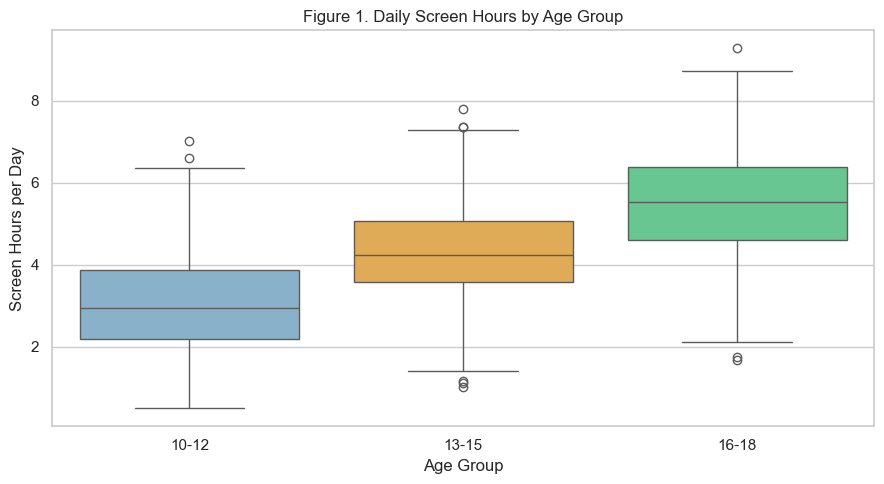

In [6]:
# Figure 1: compare total screen-time distributions by age group.
# Boxplots are chosen to show spread and outliers, not only averages.
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x='age_group', y='screen_hours_total', order=['10-12', '13-15', '16-18'], palette=['#7fb3d5', '#f5b041', '#58d68d'], ax=ax)
ax.set_title('Figure 1. Daily Screen Hours by Age Group')
ax.set_xlabel('Age Group')
ax.set_ylabel('Screen Hours per Day')
fig.tight_layout()
fig.savefig(FIG_DIR / 'figure1_screen_by_age_group.png', dpi=220)
plt.show()

## Analysis - Illustration 2: Screen Time vs Sleep

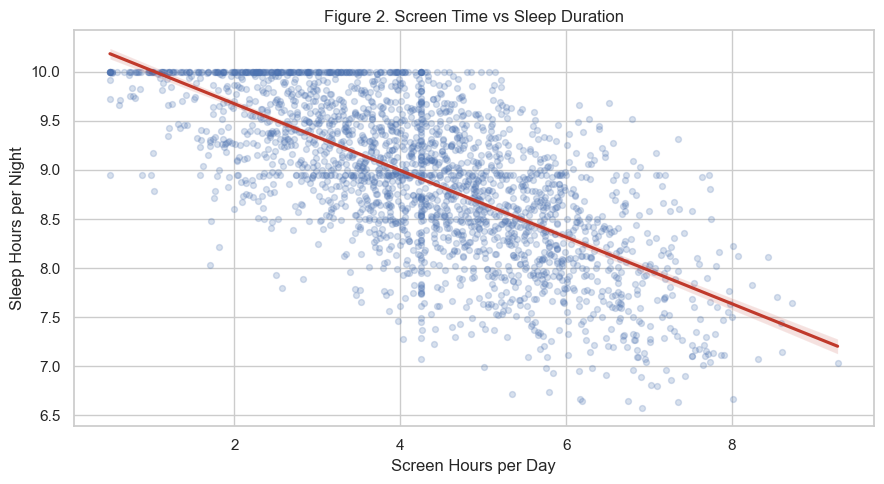

In [7]:
# Figure 2: visualize linear trend between screen exposure and sleep duration.
# Regression line helps communicate effect direction to non-technical readers quickly.
fig, ax = plt.subplots(figsize=(9, 5))
sns.regplot(data=df, x='screen_hours_total', y='sleep_hours', scatter_kws={'alpha': 0.22, 's': 18}, line_kws={'color': '#c0392b'}, ax=ax)
ax.set_title('Figure 2. Screen Time vs Sleep Duration')
ax.set_xlabel('Screen Hours per Day')
ax.set_ylabel('Sleep Hours per Night')
fig.tight_layout()
fig.savefig(FIG_DIR / 'figure2_screen_vs_sleep.png', dpi=220)
plt.show()

## Analysis - Illustration 3: Correlation Heatmap

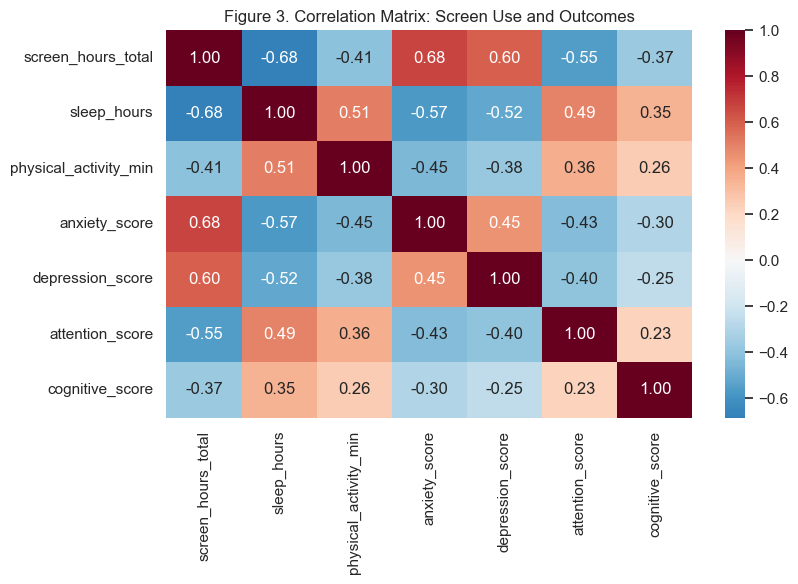

In [8]:
# Figure 3: screen all pairwise associations among core features/outcomes.
# This acts as a fast diagnostic before interpreting multivariable models.
corr_cols = ['screen_hours_total', 'sleep_hours', 'physical_activity_min', 'anxiety_score', 'depression_score', 'attention_score', 'cognitive_score']
fig, ax = plt.subplots(figsize=(8.5, 6))
mat = df[corr_cols].corr()
sns.heatmap(mat, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title('Figure 3. Correlation Matrix: Screen Use and Outcomes')
fig.tight_layout()
fig.savefig(FIG_DIR / 'figure3_correlation_heatmap.png', dpi=220)
plt.show()

## Analysis - Illustration 4: OLS Effect Estimates

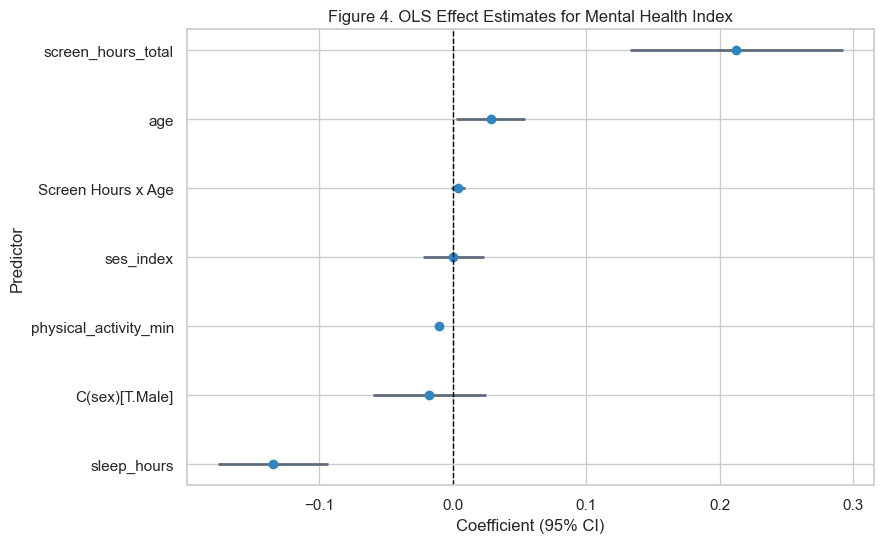

In [9]:
# Figure 4: plot OLS coefficients with 95% confidence intervals for interpretation.
# Coefficient plots make model outputs easier to compare than raw summary tables.
coef = ols.params.drop('Intercept')
conf = ols.conf_int().loc[coef.index]
coef_df = pd.DataFrame({'term': coef.index, 'coef': coef.values, 'low': conf[0].values, 'high': conf[1].values})
coef_df['term'] = coef_df['term'].str.replace('C\(sex\)\[T\.Male\]', 'Sex: Male')
coef_df['term'] = coef_df['term'].str.replace('screen_hours_total:age', 'Screen Hours x Age')
coef_df = coef_df.sort_values('coef')

fig, ax = plt.subplots(figsize=(9, 5.6))
ax.hlines(y=coef_df['term'], xmin=coef_df['low'], xmax=coef_df['high'], color='#5d6d7e', lw=2)
ax.plot(coef_df['coef'], coef_df['term'], 'o', color='#2e86c1')
ax.axvline(0, color='black', linestyle='--', lw=1)
ax.set_title('Figure 4. OLS Effect Estimates for Mental Health Index')
ax.set_xlabel('Coefficient (95% CI)')
ax.set_ylabel('Predictor')
fig.tight_layout()
fig.savefig(FIG_DIR / 'figure4_ols_coefficients.png', dpi=220)
plt.show()

## Analysis - Illustration 5: Predicted Poor Sleep Probability

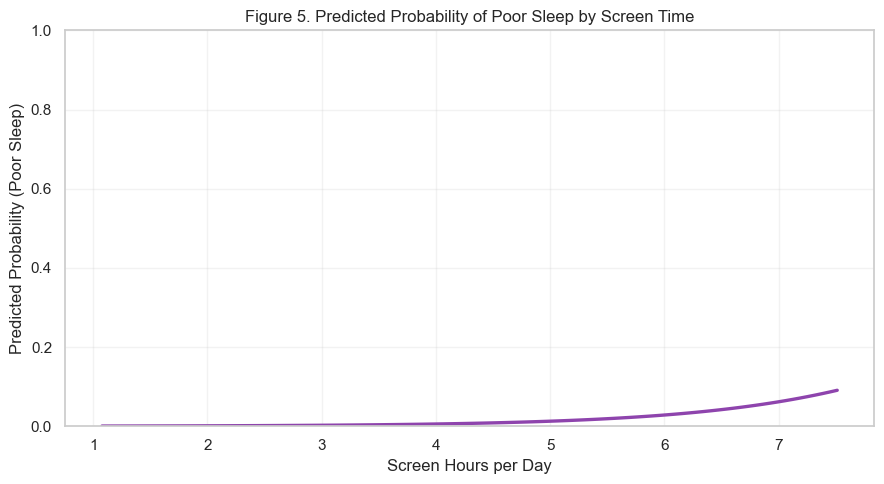

In [10]:
# Figure 5: estimated poor-sleep probability across screen-time range at typical covariates.
# Holding other variables at median values isolates the practical impact of screen exposure.
grid = pd.DataFrame({
    'screen_hours_total': np.linspace(df['screen_hours_total'].quantile(0.02), df['screen_hours_total'].quantile(0.98), 100),
    'age': np.repeat(df['age'].median(), 100),
    'sex': np.repeat('Female', 100),
    'ses_index': np.repeat(df['ses_index'].median(), 100),
    'physical_activity_min': np.repeat(df['physical_activity_min'].median(), 100),
})
grid['pred_poor_sleep'] = logit.predict(grid)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(grid['screen_hours_total'], grid['pred_poor_sleep'], color='#8e44ad', lw=2.4)
ax.set_title('Figure 5. Predicted Probability of Poor Sleep by Screen Time')
ax.set_xlabel('Screen Hours per Day')
ax.set_ylabel('Predicted Probability (Poor Sleep)')
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / 'figure5_logit_poor_sleep_curve.png', dpi=220)
plt.show()

## Key Draft Findings

In [11]:
# Final compact metrics used in the Milestone 2 narrative.
# This print block keeps the headline findings easy to copy into the white paper.
import numpy as np

or_screen = float(np.exp(logit.params['screen_hours_total']))
ci_lo, ci_hi = np.exp(logit.conf_int().loc['screen_hours_total'].values)

print(f"Correlation (screen, sleep): {df['screen_hours_total'].corr(df['sleep_hours']):.3f}")
print(f"Correlation (screen, mental index): {df['screen_hours_total'].corr(df['mental_health_index']):.3f}")
print(f"Logistic OR for screen_hours_total: {or_screen:.3f} (95% CI: {ci_lo:.3f} to {ci_hi:.3f})")
print(f"OLS beta for screen_hours_total: {ols.params['screen_hours_total']:.3f}, p={ols.pvalues['screen_hours_total']:.4g}")

Correlation (screen, sleep): -0.683
Correlation (screen, mental index): 0.748
Logistic OR for screen_hours_total: 2.256 (95% CI: 1.808 to 2.815)
OLS beta for screen_hours_total: 0.213, p=1.838e-07


## APA References
Orben, A., & Przybylski, A. K. (2019). The association between adolescent well-being and digital technology use. *Nature Human Behaviour, 3*, 173-182. https://doi.org/10.1038/s41562-018-0506-1

Twenge, J. M., & Campbell, W. K. (2018). Associations between screen time and lower psychological well-being among children and adolescents. *Preventive Medicine Reports, 12*, 271-283. https://doi.org/10.1016/j.pmedr.2018.10.003

Walsh, J. J., Barnes, J. D., Cameron, J. D., et al. (2018). Associations between 24-hour movement behaviours and global cognition in US children. *The Lancet Child & Adolescent Health, 2*(11), 783-791. https://doi.org/10.1016/S2352-4642(18)30278-5

Centers for Disease Control and Prevention. (2025). Associations between screen time use and health outcomes among US teenagers. *Preventing Chronic Disease*. https://www.cdc.gov/pcd/issues/2025/24_0537.htm

World Health Organization. (2019). *Guidelines on physical activity, sedentary behaviour and sleep for children under 5 years of age*. https://www.who.int/publications/i/item/9789241550536